# Data Analysis for AI Interviewer Assistant

## Project Overview

This notebook presents the initial data analysis for the **AI Interviewer Assistant Tool** project.

The goal of the project is to build an intelligent system that can analyze job descriptions and candidate CVs, extract relevant skills, compare the skills required by a job with the skills present in a CV, and later generate structured interview questions based on the detected competencies.

This notebook focuses on the first stage of the pipeline: **document parsing and input data analysis**. The dataset contains job descriptions and candidate CVs stored mainly as `.txt` files, while additional `.pdf` and `.docx` samples are included to test whether the parser supports multiple document formats.


## Dataset Description

The dataset is divided into three main parts:

1. **Job Descriptions**
   - Stored in `data/job_descriptions/`
   - Each file represents one job description.
   - The job descriptions include roles such as software engineer intern, web application developer intern, full-stack developer, copywriter, and other related positions.
   - Most job descriptions contain sections such as responsibilities, required skills, nice-to-have skills, tools, technologies, and benefits.

2. **Candidate CVs**
   - Stored in `data/cvs/`
   - The CVs are synthetic and anonymized.
   - They include strong IT matches, partial matches, and weak/non-IT profiles.
   - This diversity is useful for testing whether the future matching model can distinguish between suitable and unsuitable candidates.

3. **Skills Dataset**
   - Stored in `data/skills_dataset.csv`
   - Contains manually labeled IT-related skills.
   - Each skill has a category and possible aliases.
   - This dataset will later support skill extraction and matching.


## Document Parsing

The project includes a custom parser module located in `src/parser.py`.

The parser is responsible for reading different document formats and returning clean text. It supports:

- `.txt` files using normal file reading
- `.pdf` files using `PyPDF2`
- `.docx` files using `python-docx`

In this notebook, the main analysis is performed on `.txt` files because plain text is easier and more reliable for automatic processing. However, PDF and DOCX samples are also included in `data/test_documents/` to prove that the parser can handle realistic input formats.


## Loading Job Descriptions, CVs, and Skills

The following code loads all job descriptions and CVs from the project folders.

Each document is passed through the `parse_document()` function, which extracts and cleans the text. The parsed job descriptions and CVs are stored in Python dictionaries, where the key is the filename and the value is the cleaned document text.

The skills dataset is loaded as a pandas DataFrame so that it can be used later for counting and categorizing skills.


In [1]:
from pathlib import Path
import sys
import re
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# Make imports work whether the notebook is run from /notebooks or from repo root.
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.append(str(PROJECT_ROOT))

from src.parser import parse_document

JD_DIR = PROJECT_ROOT / "data" / "job_descriptions"
CV_DIR = PROJECT_ROOT / "data" / "cvs"
SKILLS_PATH = PROJECT_ROOT / "data" / "skills_dataset.csv"

jd_files = sorted(JD_DIR.glob("*.txt"))
cv_files = sorted(CV_DIR.glob("*.txt"))

jd_texts = {file.name: parse_document(str(file)) for file in jd_files}
cv_texts = {file.name: parse_document(str(file)) for file in cv_files}
skills_df = pd.read_csv(SKILLS_PATH)

print(f"Loaded {len(jd_texts)} job descriptions")
print(f"Loaded {len(cv_texts)} CVs")
print(f"Loaded {len(skills_df)} skills")


Loaded 21 job descriptions
Loaded 32 CVs
Loaded 189 skills


## Basic Dataset Statistics

Before applying NLP or semantic matching, it is useful to inspect the size and structure of the dataset.

The following analysis calculates:

- the number of job descriptions
- the number of CVs
- the average number of words per job description
- the average number of words per CV
- the minimum and maximum document length

These statistics help us understand whether the dataset is balanced and whether the documents contain enough information for meaningful skill extraction.


In [2]:
def word_count(text: str) -> int:
    return len(re.findall(r"\b\w+\b", text))

stats = pd.DataFrame([
    {
        "document_type": "job_description",
        "filename": name,
        "word_count": word_count(text),
        "character_count": len(text),
    }
    for name, text in jd_texts.items()
] + [
    {
        "document_type": "cv",
        "filename": name,
        "word_count": word_count(text),
        "character_count": len(text),
    }
    for name, text in cv_texts.items()
])

summary = stats.groupby("document_type").agg(
    documents=("filename", "count"),
    avg_words=("word_count", "mean"),
    min_words=("word_count", "min"),
    max_words=("word_count", "max"),
    avg_characters=("character_count", "mean"),
).round(2)

summary


,documents,avg_words,min_words,max_words,avg_characters
document_type,,,,,
cv,32,144.00,99,307,1127.22
job_description,21,261.76,117,918,1995.38


## Interpretation of Document Lengths

The word count statistics give an overview of how much textual information is available in the dataset.

Longer job descriptions usually contain more detailed requirements, responsibilities, and nice-to-have skills. This can improve skill extraction because the model has more context.

Shorter CVs may contain fewer explicit skills, which can make matching more difficult. However, this also reflects a realistic scenario, since candidates often provide different levels of detail in their CVs.

A dataset with varied document lengths is useful because it tests whether the system can handle both detailed and concise documents.


## Word Cloud of Job Descriptions

A word cloud is used to visualize the most frequent words appearing in the job descriptions.

Words that appear larger in the image occur more often in the dataset. This gives a quick visual overview of the dominant themes in the job descriptions, such as programming languages, frameworks, tools, responsibilities, and soft skills.

The word cloud is not a precise statistical model, but it is useful for exploratory data analysis and for identifying common terms before applying more advanced NLP techniques.


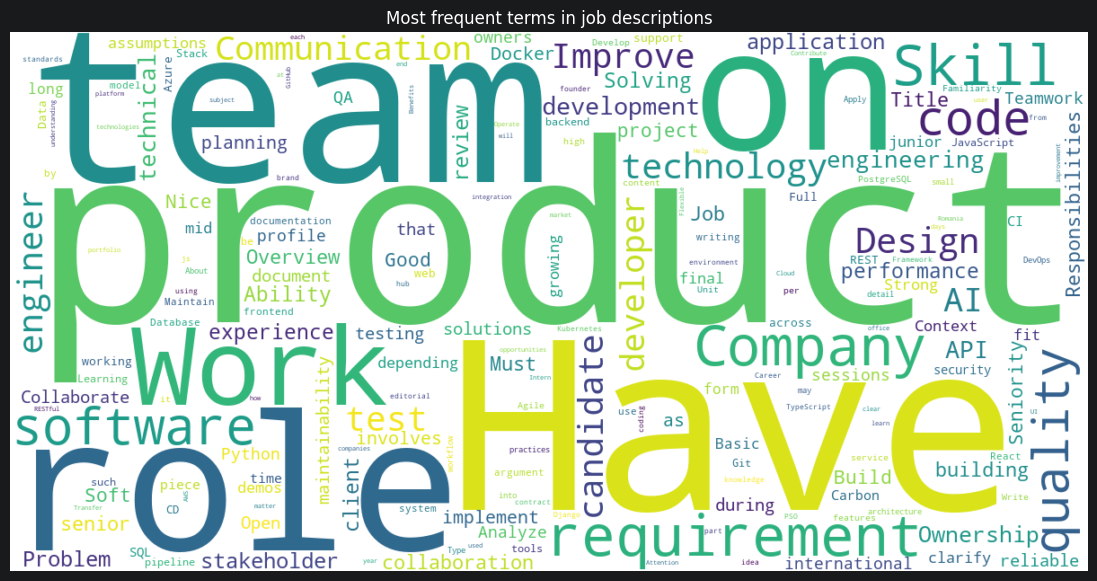

In [3]:
all_jd_text = " ".join(jd_texts.values())

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    collocations=False,
    stopwords={"and", "or", "the", "to", "of", "for", "with", "in", "a", "an", "we", "are", "is"},
).generate(all_jd_text)

plt.figure(figsize=(14, 7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Most frequent terms in job descriptions")
plt.show()


## Most Frequently Requested Skills

The next analysis counts how often skills from `skills_dataset.csv` appear in the job descriptions.

For each skill, the code searches for the main skill name and its aliases inside the job description texts. The result is a frequency count showing which skills are most commonly requested across the collected jobs.

This step is important because it helps identify the most relevant skills in the dataset and gives useful input for the next project stage: automatic skill extraction.


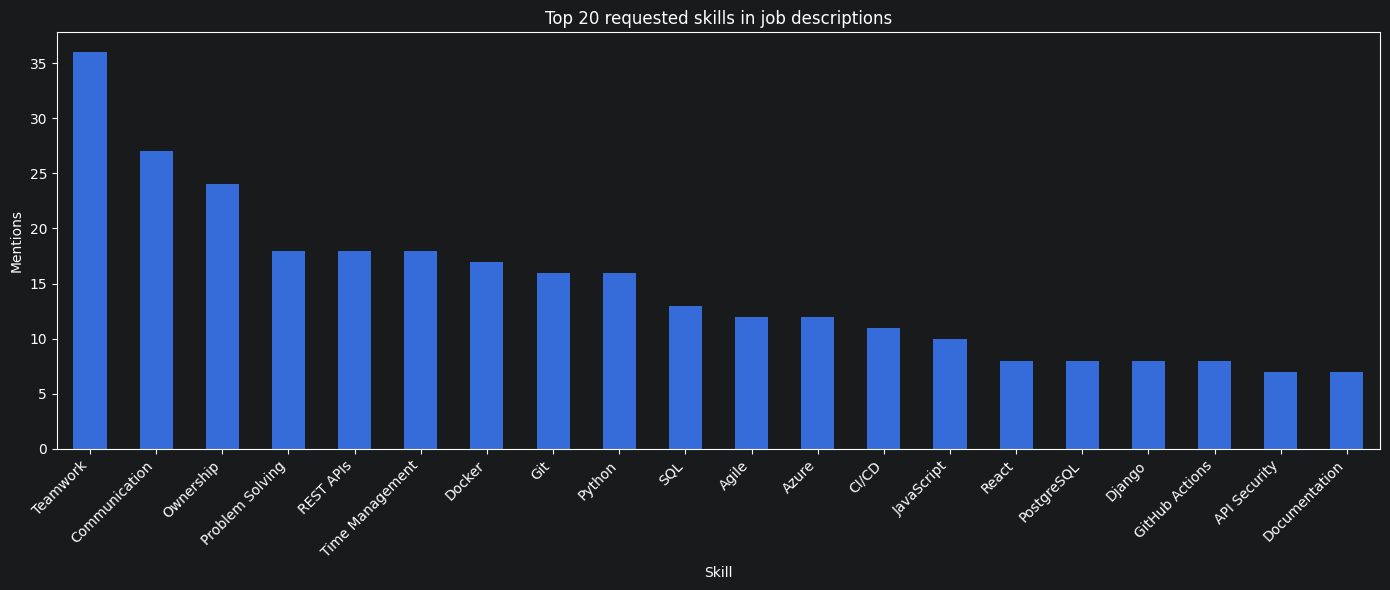

,skill_name,category,count
80,Teamwork,soft_skill,36
79,Communication,soft_skill,27
87,Ownership,soft_skill,24
81,Problem Solving,soft_skill,18
45,REST APIs,methodology,18
84,Time Management,soft_skill,18
33,Docker,devops,17
40,Git,tool,16
0,Python,programming,16
7,SQL,database,13


In [4]:
def build_skill_patterns(row):
    names = [str(row["skill_name"])]
    aliases = row.get("aliases", "")
    if pd.notna(aliases):
        names.extend([alias.strip() for alias in str(aliases).split(",") if alias.strip()])
    return list(dict.fromkeys(names))

skill_counts = []
all_jd_lower = all_jd_text.lower()

for _, row in skills_df.iterrows():
    skill_name = row["skill_name"]
    category = row["category"]
    patterns = build_skill_patterns(row)

    count = 0
    for pattern in patterns:
        regex = r"(?<![A-Za-z0-9+#.])" + re.escape(pattern.lower()) + r"(?![A-Za-z0-9+#.])"
        count += len(re.findall(regex, all_jd_lower))

    if count > 0:
        skill_counts.append({"skill_name": skill_name, "category": category, "count": count})

top_skills = pd.DataFrame(skill_counts).sort_values("count", ascending=False).head(20)

top_skills.plot(kind="bar", x="skill_name", y="count", figsize=(14, 6), legend=False)
plt.title("Top 20 requested skills in job descriptions")
plt.xlabel("Skill")
plt.ylabel("Mentions")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

top_skills


## Interpretation of the Most Frequent Skills

The bar chart shows the top skills that appear most often in the job descriptions.

Technical skills such as programming languages, frameworks, databases, APIs, testing tools, cloud platforms, and DevOps tools are expected to appear frequently in IT-related job descriptions.

If skills such as communication, collaboration, Agile, or problem-solving appear often, this shows that employers also value soft skills and teamwork, not only technical knowledge.

These results confirm that the dataset contains useful signals for later stages of the system, especially skill extraction and semantic matching.


## Distribution of Skill Categories

The skills dataset groups each skill into a category, such as:

- programming
- framework
- database
- cloud
- devops
- soft_skill
- tool
- methodology

The pie chart shows how the skills are distributed across these categories.

This helps us understand whether the skills dataset is balanced or whether it focuses too heavily on one type of competency.


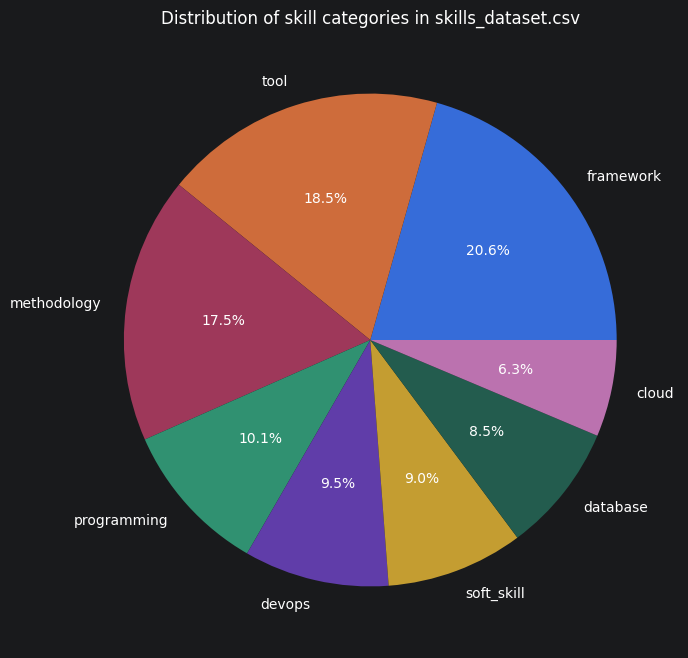

category
framework      39
tool           35
methodology    33
programming    19
devops         18
soft_skill     17
database       16
cloud          12
Name: count, dtype: int64

In [5]:
category_distribution = skills_df["category"].value_counts()

category_distribution.plot(kind="pie", autopct="%1.1f%%", figsize=(8, 8))
plt.title("Distribution of skill categories in skills_dataset.csv")
plt.ylabel("")
plt.show()

category_distribution


## Interpretation of Skill Category Distribution

The category distribution gives an overview of the types of competencies included in the skills dataset.

A balanced skills dataset is useful because job descriptions usually contain a mix of technical and non-technical requirements. For example, a software engineering role may require programming languages and frameworks, but also tools such as Git, methodologies such as Agile, and soft skills such as communication or problem-solving.

If one category dominates too strongly, the skill extraction system may become biased toward that type of skill. For this reason, the dataset includes multiple categories to support a more complete analysis of job descriptions and CVs.


## Parser Testing with PDF and DOCX Files

Although the main dataset is stored as `.txt` files, the final system should support multiple input formats because real users may upload job descriptions and CVs as PDF or Word documents.

For this reason, additional sample documents are stored in:

- `data/test_documents/pdf_jds/`
- `data/test_documents/pdf_cvs/`
- `data/test_documents/docx_jds/`
- `data/test_documents/docx_cvs/`

These files are used to verify that the parser can correctly extract text from `.pdf` and `.docx` files.


In [ ]:
test_document_dirs = [
    PROJECT_ROOT / "data" / "test_documents" / "pdf_jds",
    PROJECT_ROOT / "data" / "test_documents" / "pdf_cvs",
    PROJECT_ROOT / "data" / "test_documents" / "docx_jds",
    PROJECT_ROOT / "data" / "test_documents" / "docx_cvs",
]

test_files = []
for folder in test_document_dirs:
    if folder.exists():
        test_files.extend(sorted(folder.glob("*.pdf")))
        test_files.extend(sorted(folder.glob("*.docx")))

print(f"Found {len(test_files)} PDF/DOCX test documents.")

for file in test_files[:6]:
    parsed_text = parse_document(str(file))
    print("-" * 80)
    print(f"File: {file.name}")
    print(f"Extracted characters: {len(parsed_text)}")
    print(parsed_text[:300])


## Data Quality Notes

The dataset was designed to support the next stages of the AI Interviewer Assistant pipeline.

Some CVs are strong matches for IT job descriptions, while others are only partial matches or clearly unrelated. This is intentional because the matching model should not only identify good candidates, but also assign lower similarity scores to weak matches.

The job descriptions were cleaned and structured into consistent sections such as responsibilities, must-have skills, nice-to-have skills, technology stack, and benefits. This structure helps later NLP components detect relevant competencies more easily.


## Preliminary Conclusions

The initial dataset contains a suitable foundation for the AI Interviewer Assistant project.

The job descriptions provide structured information about responsibilities, technologies, required skills, and optional skills. The CVs provide varied candidate profiles, including strong IT matches, partial technical matches, and non-IT profiles. This variety will help test whether the future matching system can produce meaningful similarity scores.

The parser module supports TXT, PDF, and DOCX files, which makes the system more realistic and flexible for future users.

The exploratory analysis shows that the dataset contains repeated technical and soft-skill terms, making it appropriate for the next stages of the project: skill extraction, semantic matching, and interview question generation.


## Limitations and Next Steps

This dataset is relatively small and is intended for a university project prototype. A production-level system would require a larger and more diverse dataset collected from multiple industries, seniority levels, and document formats.

Another limitation is that some CVs are synthetic. This is acceptable for the current project because it avoids privacy issues and allows controlled testing, but future versions could use anonymized real CVs with permission.

The next step is to use the parsed text and the skills dataset for automatic skill extraction. This will be handled in the next notebook, where NLP techniques such as spaCy and PhraseMatcher will be used to identify skills in job descriptions and CVs.
